# Pergunta 2.1: quais features usar, e por quê?

> **Pergunta do case:** feature engineering: quais features você escolheu e por quê? Criou alguma feature nova?

**Feature** é cada coluna que o modelo recebe para fazer a previsão. É a "pista" que ele usa para adivinhar a nota.

| Passo | Pergunta |
|---|---|
| 1 | Que colunas o modelo pode ver? (o cuidado com o vazamento) |
| 2 | Como preparar cada tipo de coluna? |
| 3 | Que colunas novas ajudam? (cada uma testada com e sem) |
| 4 | As features finais repetem informação? |
| 5 | A lista final do Modelo A e do Modelo B |

Tudo usa só o **treino** (os mesmos 400 criativos da Parte 1). O teste continua guardado para o fim do notebook 2.3.

## Passo 0: preparação

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RAIZ = Path("../..")
sys.path.append(str(RAIZ))
from src.avaliacao import dobras, validar
from src.features import (ALVO, CATEGORIAS, NUMERICAS, POS_LANCAMENTO, SIM_NAO, carregar_treino_teste,
                          criar_colunas_novas, montar_pipeline)
from src.limpeza import COLUNAS_PREENCHIDAS, carregar, limpar, separar_treino_teste

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

**Mesma divisão e mesma limpeza da Parte 1**, com uma mudança: os valores que a Parte 1 preencheu voltam a vazio (o indicador `_faltava` diz quais eram). Quem preenche agora é o **Pipeline** (passo 2), só com o treino de cada rodada. Assim, nem a mediana usada para preencher "espia" os dados de validação.

Por extenso, e depois conferido contra a função `carregar_treino_teste` de `src/features.py`, que os próximos notebooks usam:

In [2]:
treino_bruto, teste_bruto = separar_treino_teste(carregar(RAIZ / "data/raw/klike_challenge_dataset.csv"))
treino = limpar(treino_bruto)
for coluna in COLUNAS_PREENCHIDAS:
    treino.loc[treino[f"{coluna}_faltava"] == 1, coluna] = np.nan
treino["retencao"] = treino["avg_watch_time_s"] / treino["video_duration_s"]  # vazia se um dos dois era vazio
treino["log_conversoes"] = np.log1p(treino["conversions"])
treino[SIM_NAO] = treino[SIM_NAO].astype(int)

treino_funcao, _ = carregar_treino_teste(RAIZ / "data/raw/klike_challenge_dataset.csv")
pd.testing.assert_frame_equal(treino, treino_funcao)
y = treino[ALVO]
print(f"Treino: {len(treino)} criativos | nota de {y.min():.1f} a {y.max():.1f}, média {y.mean():.1f}, desvio {y.std():.1f}")

Treino: 400 criativos | nota de 10.4 a 99.1, média 60.1, desvio 15.9


## Passo 1: que colunas o modelo pode ver?

O Klike promete dar a nota **antes** de o vídeo ir ao ar. Então o modelo principal só pode usar o que existe nesse momento. Usar uma coluna que só existe depois seria **vazamento de dados**: como corrigir a prova olhando o gabarito. O modelo parece ótimo no treino e não funciona no produto.

Por isso há dois modelos:

| Modelo | Para quê | Colunas |
|---|---|---|
| **A, "pré-lançamento"** (o principal) | o produto: avaliar antes de postar | atributos do vídeo + contexto da campanha |
| **B, "completo"** (régua de comparação) | medir quanto da nota o criativo sozinho já explica | o A + métricas que só existem depois de rodar |

In [3]:
ATRIBUTOS_DO_VIDEO = ["has_hook", "has_face", "has_cta", "has_subtitle", "format", "text_density",
                      "video_duration_s", "music_voice_ratio"]
CONTEXTO = ["platform", "category", "objective", "target_audience_age", "is_retargeting"]
FORA = {
    "campaign_id": "é só um código; não diz nada sobre o vídeo",
    "date / mês": "a Parte 1 não achou sazonalidade (o mês explica ~3% da nota, o mesmo que o acaso)",
    "impressions, clicks, spend, cpc, revenue, roas, cpa": "pós-lançamento e de volume (dependem do orçamento); "
                                                          "as taxas do Modelo B já resumem o que importa",
    "avg_watch_time_s": "pós-lançamento; a retenção (tempo ÷ duração) já o usa",
    "conversions": "pós-lançamento; entra no B só como log (cauda longa)",
    "colunas _faltava": "o Pipeline cria os próprios indicadores de faltante, só com o treino de cada rodada",
    "faixa_duracao, n_boas_praticas": "colunas novas: testadas no passo 3",
}
assert not set(ATRIBUTOS_DO_VIDEO + CONTEXTO) & set(POS_LANCAMENTO), "coluna pós-lançamento no Modelo A"
pd.DataFrame({"por que fica de fora": FORA}).rename_axis("coluna")

,por que fica de fora
coluna,
campaign_id,é só um código; não diz nada sobre o vídeo
date / mês,"a Parte 1 não achou sazonalidade (o mês explica ~3% da nota, o mesmo que o acaso)"
"impressions, clicks, spend, cpc, revenue, roas, cpa",pós-lançamento e de volume (dependem do orçamento); as taxas do Modelo B já resumem o ...
avg_watch_time_s,pós-lançamento; a retenção (tempo ÷ duração) já o usa
conversions,pós-lançamento; entra no B só como log (cauda longa)
colunas _faltava,"o Pipeline cria os próprios indicadores de faltante, só com o treino de cada rodada"
"faixa_duracao, n_boas_praticas",colunas novas: testadas no passo 3


## Passo 2: como preparar cada tipo de coluna?

Modelos só entendem números. Cada tipo de coluna vira número de um jeito, e tudo fica dentro de um **Pipeline**: uma "linha de montagem" do sklearn em que cada etapa aprende só com o treino e depois é aplicada igual em qualquer dado novo. É como uma receita: as medidas são decididas uma vez (no treino) e repetidas em todo bolo.

| Tipo | Colunas | Como vira número | Por quê |
|---|---|---|---|
| sim/não | gancho, rosto, CTA, retargeting | 1 = sim, 0 = não | a leitura fica direta: "ter gancho" vale X pontos |
| número com vazios | duração, música/voz | vazio vira a **mediana** do treino, e uma coluna 0/1 diz que estava vazio | a Parte 1 mostrou que os vazios não têm padrão |
| texto (categoria) | legenda, formato, texto, plataforma, categoria, objetivo, idade | **one-hot**: uma coluna 0/1 por nível, menos um | ver abaixo |
| todas | — | **padronizar** (`StandardScaler`) | ver abaixo |

- **One-hot e nível de referência:** "formato" vira "é vertical?" e "é horizontal?". O quadrado não ganha coluna: ele é a **referência**, e os pesos dizem "vertical em comparação com quadrado". É como medir a altura de todos em relação a uma pessoa da turma. As referências foram escolhidas para a leitura fazer sentido: legenda = não tem; formato = quadrado (o único nas três redes); texto = médio (o melhor na Parte 1); nas outras, o nível mais comum.
- **Legenda "desconhecido" é um nível próprio:** "não sei se tem legenda" é diferente de "não tem".
- **Padronizar** é colocar cada coluna na mesma escala (média 0, desvio 1), como converter preços em reais, dólares e euros para uma moeda só antes de comparar. Importa para a **rede neural** (notebook 2.2), que aprende dando passos de tamanho fixo: com colunas em escalas muito diferentes (segundos × 0/1), ela aprende mal. Na **regressão linear**, padronizar não muda a previsão, mas deixa os pesos comparáveis entre si (notebook 2.4). Para a **Random Forest** não importa: ela só pergunta "maior ou menor que X?", e a ordem dos valores não muda com a escala.

O Pipeline por extenso (o mesmo de `montar_pipeline`, em `src/features.py`):

In [4]:
categorias = list(CATEGORIAS)
colunas_A = SIM_NAO + NUMERICAS + categorias
pipeline_por_extenso = Pipeline([
    # 1. vazios: mediana do treino + coluna 0/1 "estava vazio"
    ("preencher", ColumnTransformer([("numericas", SimpleImputer(strategy="median", add_indicator=True), NUMERICAS)],
                                    remainder="passthrough", verbose_feature_names_out=False)),
    # 2. colunas novas (passo 3); aqui, nenhuma
    ("colunas_novas", FunctionTransformer(criar_colunas_novas, kw_args={"novas": []})),
    # 3. one-hot, com a referência de cada coluna fora
    ("codificar", ColumnTransformer([("categorias", OneHotEncoder(categories=[CATEGORIAS[c] for c in categorias],
                                                                  drop="first", sparse_output=False), categorias)],
                                    remainder="passthrough", verbose_feature_names_out=False)),
    # 4. padronizar (média 0, desvio 1)
    ("padronizar", StandardScaler()),
    ("modelo", LinearRegression()),
]).set_output(transform="pandas")
pipeline_por_extenso.fit(treino[colunas_A], y)

pela_funcao = montar_pipeline(LinearRegression(), NUMERICAS, categorias).fit(treino[colunas_A], y)
assert np.allclose(pipeline_por_extenso.predict(treino[colunas_A]), pela_funcao.predict(treino[colunas_A]))
preparado = pipeline_por_extenso[:-1].transform(treino[colunas_A])
print(f"{len(colunas_A)} colunas originais viram {preparado.shape[1]} colunas numéricas:")
print(list(preparado.columns))

13 colunas originais viram 27 colunas numéricas:
['has_subtitle_sim', 'has_subtitle_desconhecido', 'format_vertical', 'format_horizontal', 'text_density_low', 'text_density_high', 'platform_TikTok', 'platform_LinkedIn', 'category_Lead Gen', 'category_SaaS', 'category_App Install', 'category_Branding', 'objective_traffic', 'objective_engagement', 'objective_awareness', 'objective_app_install', 'target_audience_age_18-24', 'target_audience_age_35-44', 'target_audience_age_45+', 'video_duration_s', 'music_voice_ratio', 'missingindicator_video_duration_s', 'missingindicator_music_voice_ratio', 'has_hook', 'has_face', 'has_cta', 'is_retargeting']


**E se eu mantivesse o preenchimento da Parte 1?** Lá, cada vazio virou a mediana da sua plataforma, calculada com todo o treino. Numa validação cruzada, isso deixa a parte de validação influenciar o preenchimento (um vazamento pequeno). Comparo os dois jeitos com a validação cruzada do passo 3 (explicada logo abaixo):

In [5]:
preenchido_parte_1 = limpar(treino_bruto)
preenchido_parte_1[SIM_NAO] = preenchido_parte_1[SIM_NAO].astype(int)
cortes = dobras(treino)
jeitos = {
    "Pipeline (mediana geral do treino de cada rodada)": validar(montar_pipeline(LinearRegression(), NUMERICAS, categorias), treino[colunas_A], y, cortes),
    "Parte 1 (mediana da plataforma, todo o treino)": validar(montar_pipeline(LinearRegression(), NUMERICAS, categorias), preenchido_parte_1[colunas_A], y, cortes),
}
pd.DataFrame({nome: r.mean() for nome, r in jeitos.items()}).T.round(3)

,MAE,RMSE,R²
Pipeline (mediana geral do treino de cada rodada),6.954,8.705,0.691
"Parte 1 (mediana da plataforma, todo o treino)",6.919,8.648,0.695


A diferença é de centésimos de ponto. Fico com o **Pipeline**: a avaliação fica honesta (nada fora do treino de cada rodada entra no preenchimento), e o custo em erro é desprezível.

## Passo 3: que colunas novas ajudam?

Cada ideia é testada **com e sem**, com a mesma régua: **validação cruzada**. O treino é dividido em 5 partes; o modelo treina em 4 e é avaliado na 5ª, que ele não viu, e isso se repete até cada parte ter sido a prova uma vez. Repito tudo 3 vezes com sorteios diferentes: são 15 provas. É como estudar com 15 simulados diferentes em vez de um só. Os mesmos 15 cortes valem para todos os testes, então a comparação é justa.

- **Métrica:** o **MAE** (erro médio, em pontos de nota: "em média, o modelo erra X pontos"). Menor é melhor.
- **Modelo do teste:** regressão linear (explicada no notebook 2.2).
- **Regra de decisão**: uma coluna entra se reduzir o MAE em **pelo menos 1%**. Se não muda nada, decide a interpretação: fica se ajuda a explicar (e a Parte 3 precisa dela); sai se só complica.

Ideias testadas, cada uma vinda da Parte 1:

In [6]:
base = validar(montar_pipeline(LinearRegression(), NUMERICAS, categorias), treino[colunas_A], y, cortes)


def testar(ideia, origem, numericas=NUMERICAS, categorias=categorias, novas=(), modelo=LinearRegression(), referencia=base):
    """Validação cruzada com a ideia, comparada corte a corte com a referência."""
    colunas = SIM_NAO + numericas + categorias
    resultado = validar(montar_pipeline(modelo, numericas, categorias, novas), treino[colunas], y, cortes)
    diferenca = resultado["MAE"] - referencia["MAE"]
    return {"ideia": ideia, "de onde vem": origem, "MAE": resultado["MAE"].mean(), "R²": resultado["R²"].mean(),
            "variação do MAE (%)": diferenca.mean() / referencia["MAE"].mean() * 100,
            "cortes em que melhora": f"{(diferenca < 0).sum()} de {len(cortes)}"}


sem = lambda coluna: [c for c in categorias if c != coluna]
testes = pd.DataFrame([
    {"ideia": "base (todas as colunas do Modelo A)", "de onde vem": "—", "MAE": base["MAE"].mean(), "R²": base["R²"].mean(),
     "variação do MAE (%)": 0.0, "cortes em que melhora": "—"},
    testar("tirar category", "category e objective quase se definem (V de Cramér 0,59)", categorias=sem("category")),
    testar("tirar objective", "idem", categorias=sem("objective")),
    testar("texto como ordem (0, 1, 2) em vez de categoria", "Parte 1: texto tem forma de morro", novas=["texto_em_ordem"]),
    testar("n_boas_praticas (gancho + rosto + CTA + legenda)", "checklist da Parte 1", novas=["n_boas_praticas"]),
    testar("música/voz × TikTok", "Parte 1: só música, sem voz, derruba a nota no TikTok", novas=["musica_x_tiktok"]),
    testar("gancho × TikTok e gancho × LinkedIn", "Parte 1: gancho talvez pese mais no LinkedIn",
           novas=["gancho_x_tiktok", "gancho_x_linkedin"]),
    testar("duração² e música/voz²", "existe um ponto ótimo (curva)?", novas=["duracao_ao_quadrado", "musica_ao_quadrado"]),
    testar("faixas de duração", "Parte 1: não há duração ideal", novas=["duracao_ate_10s", "duracao_10_a_20s", "duracao_mais_de_30s"]),
])
testes.round(3)

,ideia,de onde vem,MAE,R²,variação do MAE (%),cortes em que melhora
0,base (todas as colunas do Modelo A),—,6.954,0.691,0.000,—
1,tirar category,"category e objective quase se definem (V de Cramér 0,59)",6.919,0.695,-0.494,10 de 15
2,tirar objective,idem,6.924,0.688,-0.427,8 de 15
3,"texto como ordem (0, 1, 2) em vez de categoria",Parte 1: texto tem forma de morro,8.356,0.556,20.173,0 de 15
4,n_boas_praticas (gancho + rosto + CTA + legenda),checklist da Parte 1,6.954,0.691,-0.000,8 de 15
5,música/voz × TikTok,"Parte 1: só música, sem voz, derruba a nota no TikTok",6.936,0.694,-0.249,9 de 15
6,gancho × TikTok e gancho × LinkedIn,Parte 1: gancho talvez pese mais no LinkedIn,6.963,0.691,0.136,10 de 15
7,duração² e música/voz²,existe um ponto ótimo (curva)?,6.935,0.692,-0.271,9 de 15
8,faixas de duração,Parte 1: não há duração ideal,6.993,0.685,0.571,8 de 15


**Lendo os testes:**

- **Nenhuma ideia passa da régua de 1%:** as melhoras vão de 0,0% a 0,5%, menores que a diferença entre um corte e outro. O Modelo A já capta quase tudo com as colunas originais.
- **Texto como ordem piora o erro em 20%** (nenhum corte melhora). Confirma a Parte 1: o meio é o melhor, e uma ordem 0-1-2 força uma reta. **O texto fica como categoria.**
- **`category` sai:** tirá-la não perde nada (o erro até cai 0,5%, em 10 de 15 cortes). Ela repete o `objective`. Fico com o `objective` porque é a escolha que o time faz em cada campanha, e a Parte 1 mostrou que a boa métrica depende dele.
- **`n_boas_praticas` não muda nada no linear** (0,0%): é a soma exata de quatro colunas que o modelo já tem.
- **Música/voz × TikTok fica**, mesmo abaixo da régua (−0,2%, melhora em 9 de 15 cortes): não piora, confirma a Parte 1 e dá à Parte 3 uma recomendação própria do TikTok ("coloque voz").
- **Saem:** gancho × rede (não melhora), duração² e música/voz² (−0,3%, sem nada novo a explicar: a Parte 1 já mostrou que não há duração ideal) e faixas de duração (pioram 0,6%).

**O n_boas_praticas na Random Forest.** Para um modelo linear, `n_boas_praticas` é só a soma de quatro colunas que ele já tem, então não acrescenta nada. Uma árvore, porém, só faz perguntas sobre uma coluna de cada vez; a soma pronta pode ajudar. Testo com a Random Forest (explicada no notebook 2.2):

In [7]:
floresta = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5, random_state=42, n_jobs=-1)
base_floresta = validar(montar_pipeline(floresta, NUMERICAS, categorias), treino[colunas_A], y, cortes)
pd.DataFrame([
    {"ideia": "Random Forest, base", "MAE": base_floresta["MAE"].mean(), "R²": base_floresta["R²"].mean()},
    testar("Random Forest + n_boas_praticas", "", novas=["n_boas_praticas"], modelo=floresta, referencia=base_floresta),
]).drop(columns="de onde vem", errors="ignore").round(3)

,ideia,MAE,R²,variação do MAE (%),cortes em que melhora
0,"Random Forest, base",7.870,0.618,NaN,NaN
1,Random Forest + n_boas_praticas,7.514,0.636,-4.518,13 de 15


**Na Random Forest, `n_boas_praticas` ajuda:** o erro cai 4,5%, em 13 de 15 cortes. Passa da régua, então entra **só na Random Forest** (notebook 2.2). Para o modelo linear, continua de fora.

## Passo 4: as features finais repetem informação?

Quando duas colunas andam muito juntas (correlação alta), o modelo linear não sabe a qual dar o crédito: os pesos ficam **instáveis** (mudam muito de uma amostra para outra), mesmo que a previsão continue boa. Mapa de correlação das colunas que o Modelo A recebe, depois do one-hot:

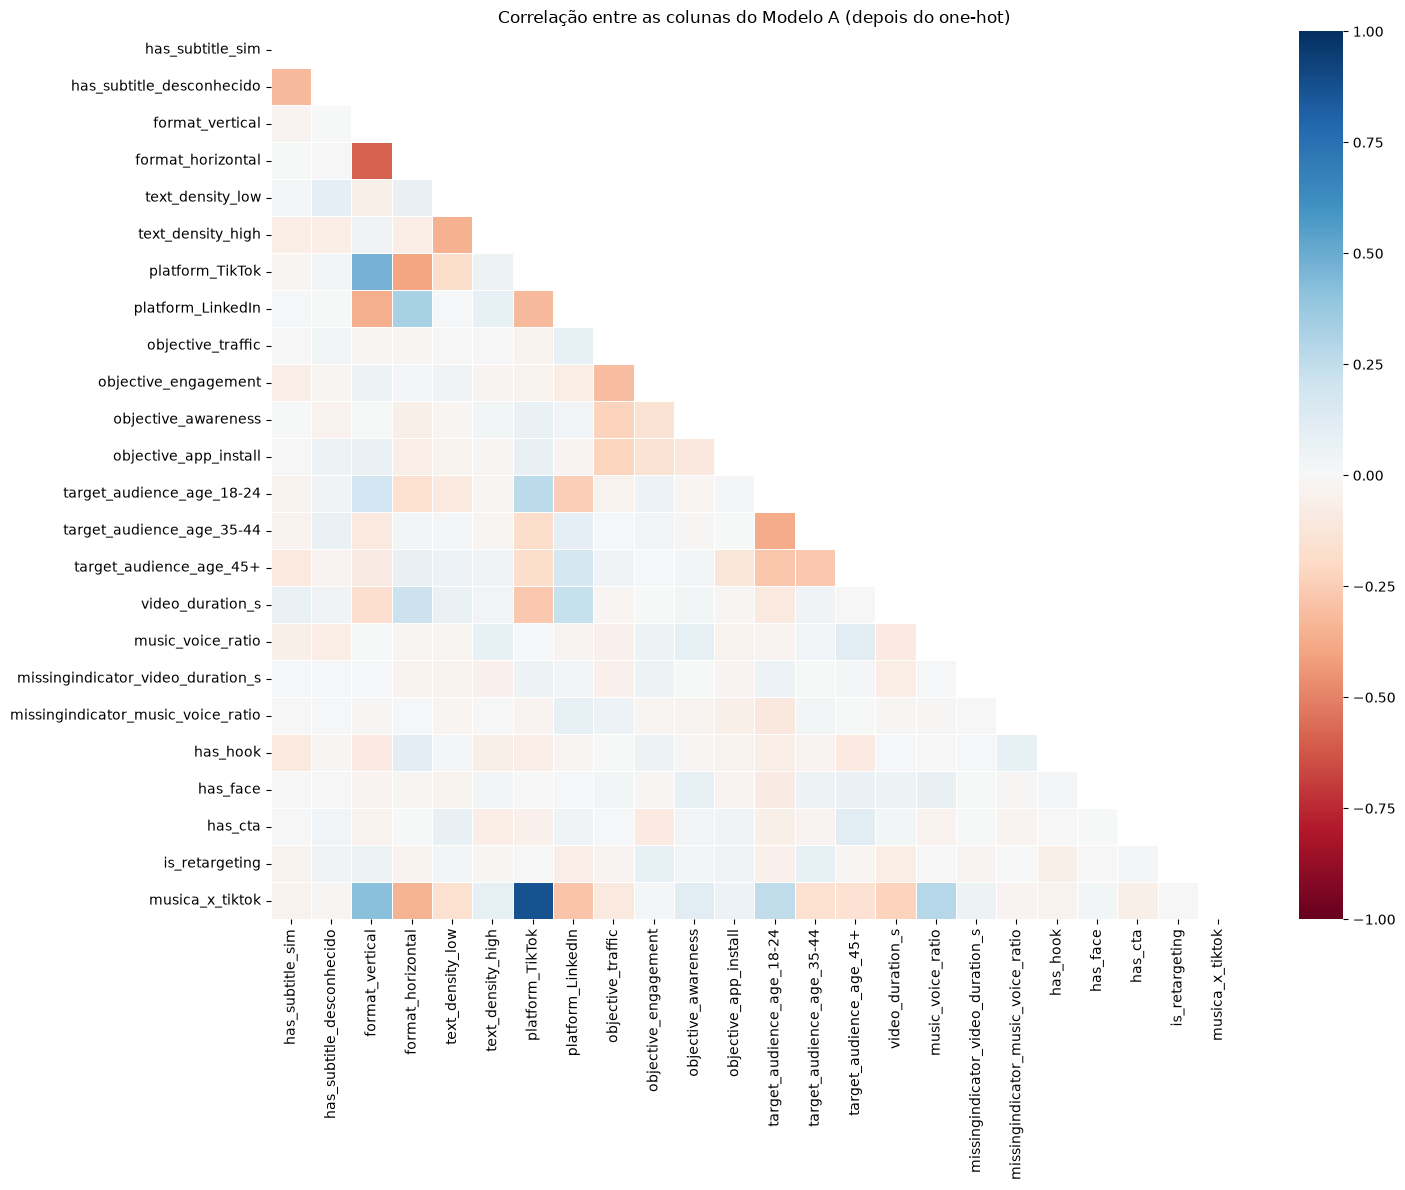

,,correlação
platform_TikTok,musica_x_tiktok,0.87


In [8]:
categorias_A = sem("category")
NOVAS_A = ["musica_x_tiktok"]
colunas_A = SIM_NAO + NUMERICAS + categorias_A
preparado = montar_pipeline(LinearRegression(), NUMERICAS, categorias_A, NOVAS_A)[:3].fit_transform(treino[colunas_A])
correlacao = preparado.corr()

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(correlacao, cmap="RdBu", center=0, vmin=-1, vmax=1, ax=ax, linewidths=0.5,
            mask=np.triu(np.ones_like(correlacao, dtype=bool)))
ax.set_title("Correlação entre as colunas do Modelo A (depois do one-hot)")
plt.tight_layout()
plt.show()

acima = correlacao.where(np.triu(np.ones(correlacao.shape, dtype=bool), k=1)).stack()
acima[acima.abs() > 0.6].round(2).rename("correlação").to_frame()

**Lendo o mapa:**

- **Só um par passa de 0,6:** `platform_TikTok` × `musica_x_tiktok` (0,87). É esperado: a coluna nova só existe no TikTok. A consequência é que os pesos das duas dividem o crédito e ficam menos estáveis; elas devem ser lidas juntas ("no TikTok, quanto vale a música").
- **O resto anda pouco junto.** O par mais problemático da Parte 1 (`category` × `objective`) foi resolvido no passo 3, tirando a `category`. Os pesos dos atributos do vídeo devem ficar estáveis (conferido no notebook 2.4).

## Passo 5: a lista final

Repetindo a validação cruzada com o conjunto final do Modelo A, e com o Modelo B (o A + as métricas pós-lançamento):

In [9]:
colunas_B = colunas_A + POS_LANCAMENTO
numericas_B = NUMERICAS + POS_LANCAMENTO
final_A = validar(montar_pipeline(LinearRegression(), NUMERICAS, categorias_A, NOVAS_A), treino[colunas_A], y, cortes)
final_B = validar(montar_pipeline(LinearRegression(), numericas_B, categorias_A, NOVAS_A), treino[colunas_B], y, cortes)
assert not set(colunas_A) & set(POS_LANCAMENTO), "coluna pós-lançamento no Modelo A"
print("Modelo A:", colunas_A, "+", NOVAS_A)
print("Modelo B: o A +", POS_LANCAMENTO)
pd.DataFrame({"Modelo A (pré-lançamento)": final_A.mean(), "Modelo B (completo)": final_B.mean()}).T.round(3)

Modelo A: ['has_hook', 'has_face', 'has_cta', 'is_retargeting', 'video_duration_s', 'music_voice_ratio', 'has_subtitle', 'format', 'text_density', 'platform', 'objective', 'target_audience_age'] + ['musica_x_tiktok']
Modelo B: o A + ['ctr', 'engagement_rate', 'retencao', 'taxa_conversao', 'cpm', 'log_conversoes']


,MAE,RMSE,R²
Modelo A (pré-lançamento),6.894,8.596,0.698
Modelo B (completo),5.616,7.078,0.794


In [10]:
ORIGEM = {
    "has_hook, has_face, has_cta": ("atributo do vídeo", "A e B", "gancho e rosto: os maiores efeitos da Parte 1; CTA soma pontos"),
    "has_subtitle (sim / não / desconhecido)": ("atributo do vídeo", "A e B", "legenda soma ~8 pontos; 'desconhecido' é um nível próprio"),
    "text_density (pouco / médio / muito)": ("atributo do vídeo", "A e B", "ponto ótimo no meio: como categoria, não como ordem"),
    "format": ("atributo do vídeo", "A e B", "pouco efeito na nota, mas é decisão do time e a Parte 3 precisa dele"),
    "video_duration_s, music_voice_ratio (+ indicador de vazio)": ("atributo do vídeo", "A e B", "efeito pequeno; entram como número"),
    "musica_x_tiktok (nova)": ("criada aqui", "A e B", "só música, sem voz, pesa no TikTok (Parte 1)"),
    "platform, objective, target_audience_age, is_retargeting": ("contexto da campanha", "A e B", "sabido antes de postar; controla o público"),
    "ctr, engagement_rate, retencao, taxa_conversao, cpm": ("pós-lançamento", "só B", "medem o resultado: só existem depois de rodar"),
    "log_conversoes (nova)": ("pós-lançamento", "só B", "conversões têm cauda longa; o log a encolhe"),
}
pd.DataFrame(ORIGEM, index=["de onde vem", "modelo", "por que entra"]).T.rename_axis("feature")

,de onde vem,modelo,por que entra
feature,,,
"has_hook, has_face, has_cta",atributo do vídeo,A e B,gancho e rosto: os maiores efeitos da Parte 1; CTA soma pontos
has_subtitle (sim / não / desconhecido),atributo do vídeo,A e B,legenda soma ~8 pontos; 'desconhecido' é um nível próprio
text_density (pouco / médio / muito),atributo do vídeo,A e B,"ponto ótimo no meio: como categoria, não como ordem"
format,atributo do vídeo,A e B,"pouco efeito na nota, mas é decisão do time e a Parte 3 precisa dele"
"video_duration_s, music_voice_ratio (+ indicador de vazio)",atributo do vídeo,A e B,efeito pequeno; entram como número
musica_x_tiktok (nova),criada aqui,A e B,"só música, sem voz, pesa no TikTok (Parte 1)"
"platform, objective, target_audience_age, is_retargeting",contexto da campanha,A e B,sabido antes de postar; controla o público
"ctr, engagement_rate, retencao, taxa_conversao, cpm",pós-lançamento,só B,medem o resultado: só existem depois de rodar
log_conversoes (nova),pós-lançamento,só B,conversões têm cauda longa; o log a encolhe


## Resposta à pergunta 2.1: quais features escolhi, por quê, e criei alguma nova?

> 💡 **Conclusão**
>
> - **Escolhi, para o Modelo A (pré-lançamento), as 12 colunas que existem antes de postar:** os 8 atributos do vídeo (gancho, rosto, CTA, legenda, formato, texto na tela, duração, música/voz) e 4 de contexto (plataforma, objetivo, idade do público, retargeting). Nenhuma coluna pós-lançamento entra, porque o Klike avalia antes de postar (há uma checagem no código). Na validação cruzada, ele erra em média 6,9 pontos (R² 0,70).
> - **Por quê:** cada uma veio da Parte 1 e foi testada com e sem. O texto na tela entra como **categoria** (como ordem, o erro sobe 20%: o meio é o melhor). A `category` saiu, porque repete o objetivo. Data, `campaign_id` e métricas de volume ficaram de fora.
> - **Criei colunas novas:** a **música/voz × TikTok** (fica: confirma a Parte 1 e dá uma regra própria do TikTok para a Parte 3) e o **`n_boas_praticas`** (só na Random Forest, onde corta 4,5% do erro). O Modelo B usa também o **log das conversões**. As outras ideias (interações com o gancho, curvas, faixas de duração) não ajudaram e saíram.
> - **Modelo B (completo):** o A + 6 métricas que só existem depois de rodar. Erra 5,6 pontos (R² 0,79). A diferença entre os dois é o que só se descobre depois de postar.